### Esempio Pratico: Calcolo Passo Passo

Consideriamo un piccolo dataset scolastico con 4 studenti divisi in 2 classi ($X$), di cui registriamo il voto finale ($Y$):
*   **Classe A ($X=A$):** Voti 4, 6
*   **Classe B ($X=B$):** Voti 8, 12

Applichiamo la Legge della Varianza Totale calcolando manualmente i due blocchi.

**1. Varianza Non Spiegata (Intra-gruppo): $E[Var(Y|X)]$**
Calcoliamo la varianza interna di ogni singola classe rispetto alla sua stessa media:
*   Media A = 5 $\rightarrow$ Varianza A = $\frac{(4-5)^2 + (6-5)^2}{2} = 1$
*   Media B = 10 $\rightarrow$ Varianza B = $\frac{(8-10)^2 + (12-10)^2}{2} = 4$
*   Essendo i gruppi di uguale dimensione, il Valore Atteso (media) delle varianze è: $\frac{1 + 4}{2} = 2.5$

**2. Varianza Spiegata (Tra-gruppi): $Var(E[Y|X])$**
Calcoliamo quanto le medie dei singoli gruppi si discostano dalla media globale di tutti gli studenti (che è 7.5):
*   Varianza delle Medie: $\frac{(5-7.5)^2 + (10-7.5)^2}{2} = 6.25$

**Somma e Verifica sulla Varianza Totale:**
*   Somma delle componenti (Legge di Eve): $2.5 + 6.25 = 8.75$
*   Calcolo diretto della varianza su tutti i voti aggregati [4, 6, 8, 12]: $\frac{(4-7.5)^2 + (6-7.5)^2 + (8-7.5)^2 + (12-7.5)^2}{4} = 8.75$

TypeError: 'module' object is not callable

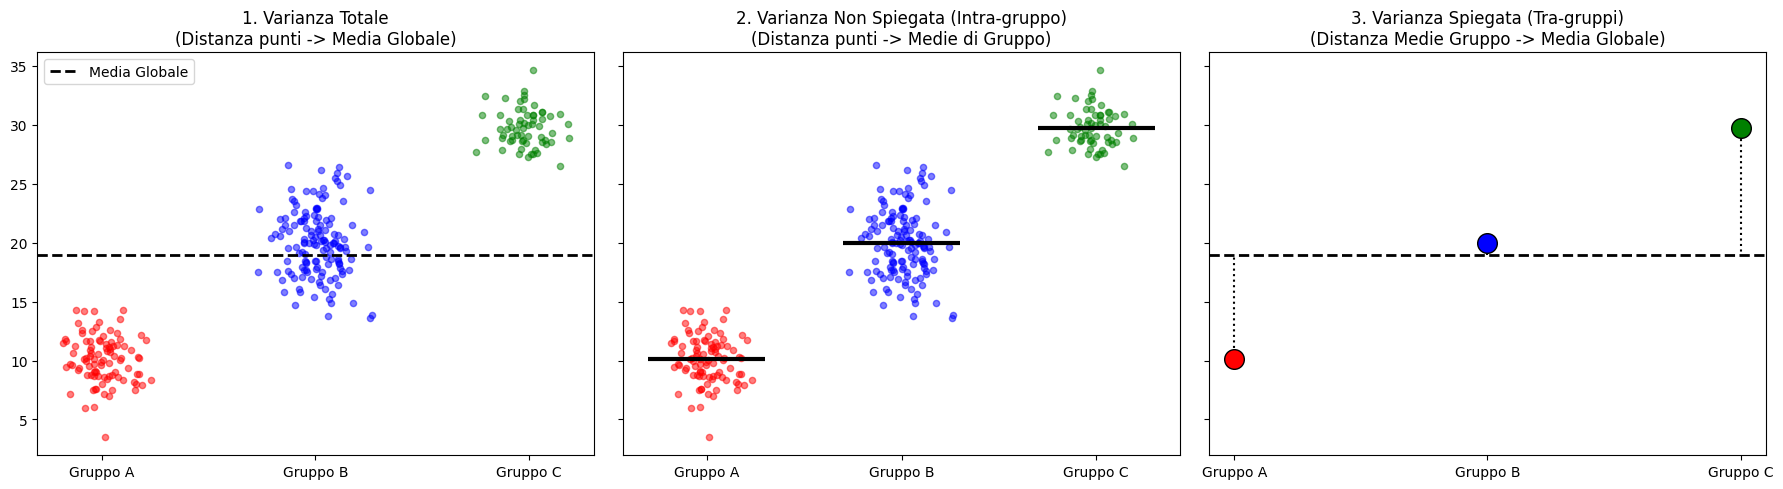

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Generazione dei dati (come nell'esempio precedente)
np.random.seed(42)
n_samples = 300

X = np.random.choice(['Gruppo A', 'Gruppo B', 'Gruppo C'], size=n_samples, p=[0.3, 0.5, 0.2])

Y = np.zeros(n_samples)
Y[X == 'Gruppo A'] = np.random.normal(loc=10, scale=2, size=sum(X == 'Gruppo A'))
Y[X == 'Gruppo B'] = np.random.normal(loc=20, scale=3, size=sum(X == 'Gruppo B'))
Y[X == 'Gruppo C'] = np.random.normal(loc=30, scale=1.5, size=sum(X == 'Gruppo C'))

# Calcoli delle medie e varianze
media_totale = np.mean(Y)
var_totale = np.var(Y)

gruppi = ['Gruppo A', 'Gruppo B', 'Gruppo C']
medie_gruppi = {g: np.mean(Y[X == g]) for g in gruppi}
var_gruppi = {g: np.var(Y[X == g]) for g in gruppi}
pesi_gruppi = {g: sum(X == g)/n_samples for g in gruppi}

# Varianza Non Spiegata (Intra-gruppo)
var_non_spiegata = sum(var_gruppi[g] * pesi_gruppi[g] for g in gruppi)

# Varianza Spiegata (Tra-gruppi)
media_delle_medie = sum(medie_gruppi[g] * pesi_gruppi[g] for g in gruppi)
var_spiegata = sum(((medie_gruppi[g] - media_delle_medie)**2) * pesi_gruppi[g] for g in gruppi)

# 2. Creazione dei Grafici Visivi
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Colori per i gruppi
colors = {'Gruppo A': 'red', 'Gruppo B': 'blue', 'Gruppo C': 'green'}
x_jitter = np.random.normal(0, 0.1, size=n_samples) # per visualizzare meglio i punti

# Plot 1: Varianza Totale (Punti vs Media Globale)
for g in gruppi:
    mask = X == g
    x_pos = [gruppi.index(g)] * sum(mask) + x_jitter[mask]
    axes[0].scatter(x_pos, Y[mask], color=colors[g], alpha=0.5, s=20)
axes[0].axhline(media_totale, color='black', linestyle='--', linewidth=2, label='Media Globale')
axes[0].set_title("1. Varianza Totale\n(Distanza punti -> Media Globale)")
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(gruppi)
axes[0].legend()

# Plot 2: Varianza Non Spiegata (Punti vs Medie di Gruppo)
for g in gruppi:
    mask = X == g
    x_pos = [gruppi.index(g)] * sum(mask) + x_jitter[mask]
    axes[1].scatter(x_pos, Y[mask], color=colors[g], alpha=0.5, s=20)
    # Linea della media del gruppo
    axes[1].hlines(medie_gruppi[g], xmin=gruppi.index(g)-0.3, xmax=gruppi.index(g)+0.3, 
                   colors='black', linewidth=3, label=f'Media {g}' if g == 'Gruppo A' else "")
axes[1].set_title("2. Varianza Non Spiegata (Intra-gruppo)\n(Distanza punti -> Medie di Gruppo)")
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(gruppi)

# Plot 3: Varianza Spiegata (Medie di Gruppo vs Media Globale)
for g in gruppi:
    axes[2].scatter(gruppi.index(g), medie_gruppi[g], color=colors[g], s=200, edgecolor='black', zorder=5)
    axes[2].plot([gruppi.index(g), gruppi.index(g)], [medie_gruppi[g], media_totale], color='black', linestyle=':')
axes[2].axhline(media_totale, color='black', linestyle='--', linewidth=2, label='Media Globale')
axes[2].set_title("3. Varianza Spiegata (Tra-gruppi)\n(Distanza Medie Gruppo -> Media Globale)")
axes[2].set_xticks([0, 1, 2])
axes[2].set_xticklabels(gruppi)

plt.tight_layout()
plt('varianza_visiva.png', dpi=150)
plt.close()

print(f"Var Totale: {var_totale:.2f}")
print(f"Var Non Spiegata: {var_non_spiegata:.2f}")
print(f"Var Spiegata: {var_spiegata:.2f}")

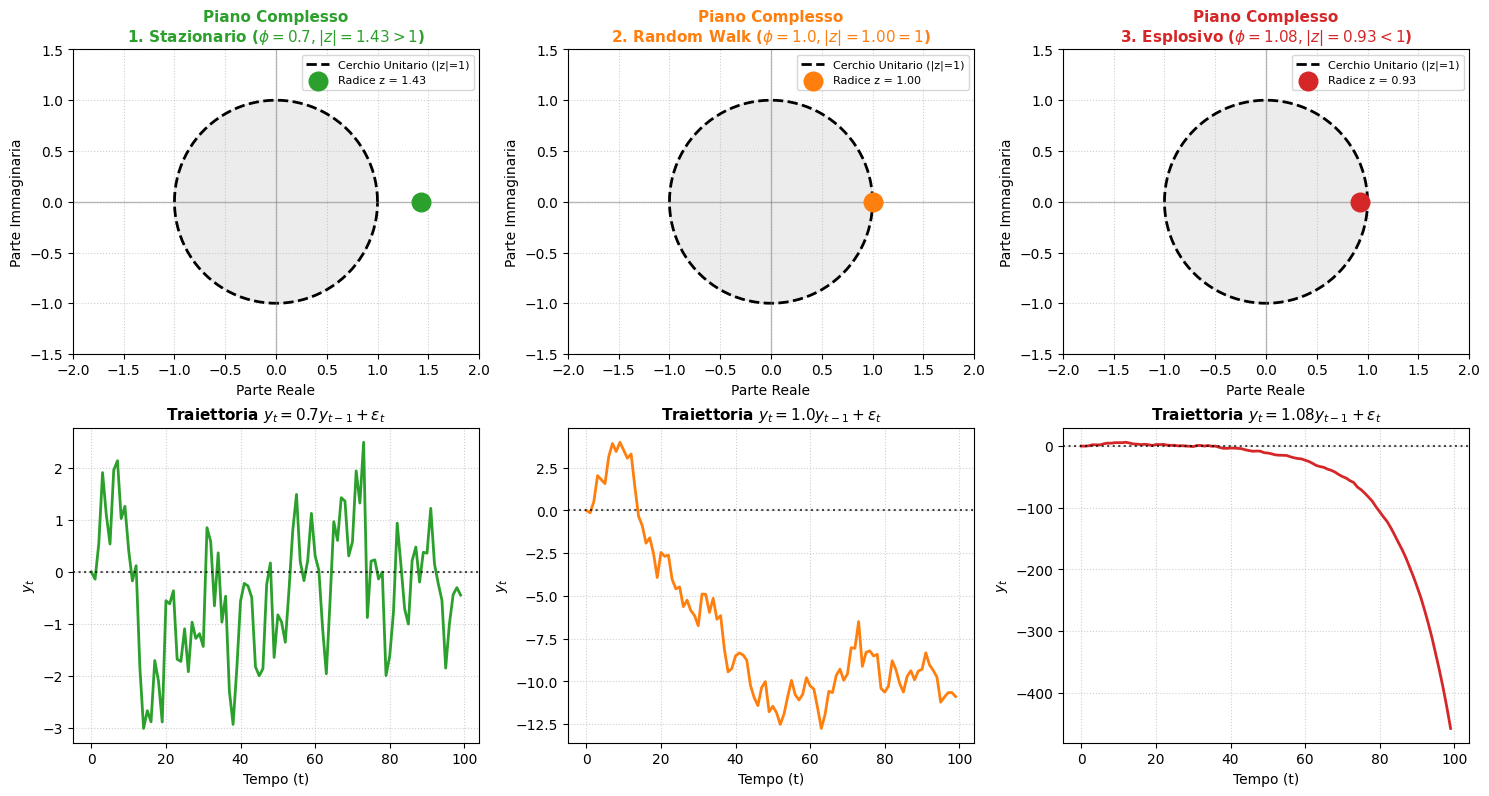

In [13]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
T = 100
e = np.random.normal(0, 1, T)

# Valori di phi e relative etichette
phis = [0.7, 1.0, 1.08]
labels = [
    r'1. Stazionario ($\phi=0.7, |z|=1.43 > 1$)',
    r'2. Random Walk ($\phi=1.0, |z|=1.00 = 1$)',
    r'3. Esplosivo ($\phi=1.08, |z|=0.93 < 1$)'
]
colors = ['#2ca02c', '#ff7f0e', '#d62728']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Generazione circonferenza del cerchio unitario
theta = np.linspace(0, 2*np.pi, 200)
unit_circle_x = np.cos(theta)
unit_circle_y = np.sin(theta)

for i, phi in enumerate(phis):
    z = 1.0 / phi
    
    # 1. Piano Complesso
    ax_complex = axes[0, i]
    ax_complex.plot(unit_circle_x, unit_circle_y, 'k--', linewidth=2, label='Cerchio Unitario (|z|=1)')
    ax_complex.fill(unit_circle_x, unit_circle_y, color='gray', alpha=0.15)
    ax_complex.scatter([z], [0], color=colors[i], s=180, zorder=5, label=f'Radice z = {z:.2f}')
    ax_complex.axhline(0, color='gray', alpha=0.5, linewidth=1)
    ax_complex.axvline(0, color='gray', alpha=0.5, linewidth=1)
    ax_complex.set_xlim(-2.0, 2.0)
    ax_complex.set_ylim(-1.5, 1.5)
    ax_complex.set_aspect('equal')
    ax_complex.set_title(f'Piano Complesso\n{labels[i]}', fontsize=11, fontweight='bold', color=colors[i])
    ax_complex.set_xlabel('Parte Reale')
    ax_complex.set_ylabel('Parte Immaginaria')
    ax_complex.legend(loc='upper right', fontsize=8)
    ax_complex.grid(True, linestyle=':', alpha=0.6)
    
    # 2. Serie Storica
    ax_ts = axes[1, i]
    y = np.zeros(T)
    for t in range(1, T):
        y[t] = phi * y[t-1] + e[t]
        
    ax_ts.plot(y, color=colors[i], linewidth=2)
    ax_ts.axhline(0, color='black', linestyle=':', alpha=0.7)
    ax_ts.set_title(f'Traiettoria $y_t = {phi} y_{{t-1}} + \epsilon_t$', fontsize=11, fontweight='bold')
    ax_ts.set_xlabel('Tempo (t)')
    ax_ts.set_ylabel('$y_t$')
    ax_ts.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Trasformare un ARMA(1,1) in una somma di Shock (MA infinito)

Abbiamo visto matematicamente che un processo ARMA(1,1) può essere "srotolato" per dipendere solo ed esclusivamente dalle notizie (shock) passate. 
La formula che ci dice **quanto pesa oggi** una notizia di $j$ giorni fa è:

*   **Lag 0 (Oggi):** Il peso è sempre $1$. (La notizia di oggi impatta al 100%).
*   **Lag j (Passato):** Il peso è $\psi_j = \phi^{j-1}(\phi + \psi)$.

Scriviamo una funzione Python per calcolare questi pesi e visualizzare come le notizie invecchiano e perdono importanza nel tempo.

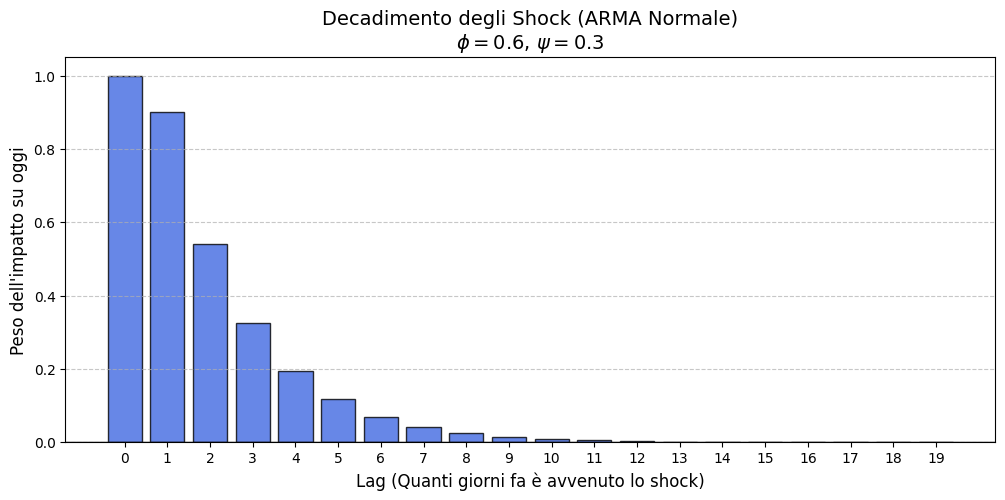

In [14]:
import numpy as np
import matplotlib.pyplot as plt

def calcola_pesi_ma_infinito(phi, psi, max_lags=20):
    """
    Calcola i coefficienti (pesi) per trasformare un ARMA(1,1) in un MA(infinito).
    Mostra l'impatto di uno shock passato sul prezzo di oggi.
    """
    pesi = np.zeros(max_lags)
    
    # Lo shock di oggi (lag 0) ha sempre un impatto diretto di 1
    pesi[0] = 1.0 
    
    # Calcolo del peso per tutti gli shock passati (lag da 1 in poi)
    for j in range(1, max_lags):
        pesi[j] = (phi**(j-1)) * (phi + psi)
        
    return pesi

# --- SIMULAZIONE 1: ARMA(1,1) STANDARD ---
# Scegliamo un'inerzia moderata (phi) e un eco positivo (psi)
phi_normale = 0.6
psi_normale = 0.3

pesi_normali = calcola_pesi_ma_infinito(phi_normale, psi_normale)

# Visualizzazione
plt.figure(figsize=(12, 5))
plt.bar(range(20), pesi_normali, color='royalblue', edgecolor='black', alpha=0.8)
plt.axhline(0, color='black', linewidth=1)
plt.title(f"Decadimento degli Shock (ARMA Normale)\n$\phi={phi_normale}$, $\psi={psi_normale}$", fontsize=14)
plt.xlabel("Lag (Quanti giorni fa è avvenuto lo shock)", fontsize=12)
plt.ylabel("Peso dell'impatto su oggi", fontsize=12)
plt.xticks(range(20))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Il Caso Limite: White Noise (Rumore Bianco)

Cosa succede se specifichiamo male il nostro modello e inseriamo un parametro AR ($\phi$) e un parametro MA ($\psi$) che hanno forze **esattamente uguali e contrarie**?

Matematicamente poniamo $\phi = -\psi$. 
Il risultato è la **Cancellazione delle Radici Comuni**: l'inerzia viene uccisa dall'eco. Il modello perde ogni memoria del passato e l'unico shock che conta rimane quello di oggi, trasformando la serie in un puro rumore casuale.

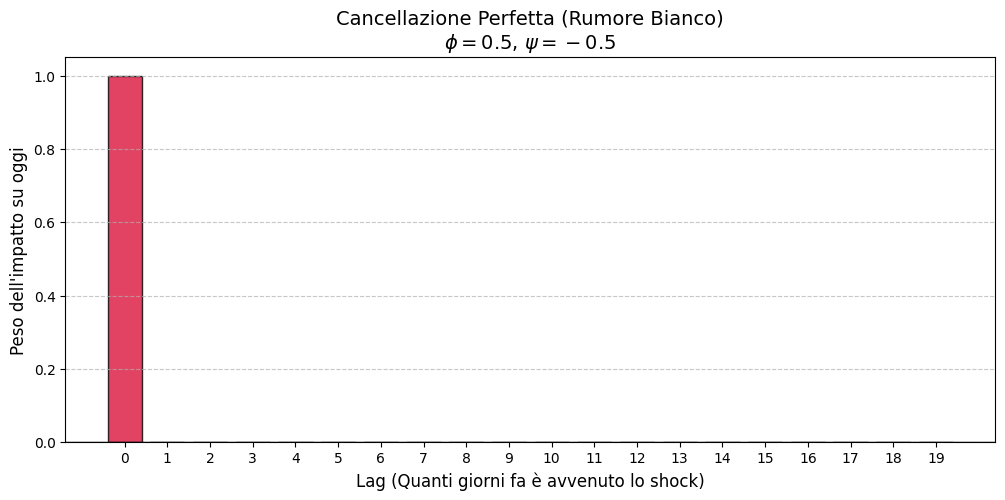

Valori esatti dei pesi calcolati dal programma:
Lag 0: 1.0
Lag 1: 0.0
Lag 2: 0.0
Lag 3: 0.0
Lag 4: 0.0


In [15]:
# --- SIMULAZIONE 2: PARAMETRIZZAZIONE RIDONDANTE ---
# Impostiamo psi in modo che sia l'esatto opposto di phi
phi_wn = 0.5
psi_wn = -0.5

pesi_wn = calcola_pesi_ma_infinito(phi_wn, psi_wn)

# Visualizzazione
plt.figure(figsize=(12, 5))
plt.bar(range(20), pesi_wn, color='crimson', edgecolor='black', alpha=0.8)
plt.axhline(0, color='black', linewidth=1)
plt.title(f"Cancellazione Perfetta (Rumore Bianco)\n$\phi={phi_wn}$, $\psi={psi_wn}$", fontsize=14)
plt.xlabel("Lag (Quanti giorni fa è avvenuto lo shock)", fontsize=12)
plt.ylabel("Peso dell'impatto su oggi", fontsize=12)
plt.xticks(range(20))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Stampiamo i valori per conferma
print("Valori esatti dei pesi calcolati dal programma:")
for lag, peso in enumerate(pesi_wn[:5]): # Stampiamo solo i primi 5 lag
    print(f"Lag {lag}: {peso}")